# Preprocessing evaluation
UMI/area/gene-detection QC and patch/label-distribution overview for histology and transcriptomics preprocessing, split out of `new_single_omics.ipynb` (label-transfer and latent-embedding evaluation stay there).

In [1]:
from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.neighbors import KNeighborsClassifier
import gc

%load_ext autoreload
%autoreload 2

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt

In [2]:
basedir = Path("../data")
dir_uni =  "01_preprocessing/unimodel/metadata"
samples = ["CRC_P1", "CRC_P2", "CRC_P3_SMAP", "CRC_P4_SMAP", "CRC_P5", "Normal_P3", "Normal_P5", "CRC_P6_5mm", "CRC_P11mm", "CRC_P11mm_2_cut"]

def label_transfer_dir(sample_id):
    """data/{sample}/02_baselines/label_transfer -- matches functions/label_transfer.py's OUT_DIR_TEMPLATE."""
    return basedir / sample_id / "02_baselines/label_transfer"


## Histology

#### Evaluation of preprocessing steps
This first cell gives us an overview over some basic information such as patch count and disease status prediction of the label transfer.

In [3]:
meta = ad.read_h5ad(basedir / "combined" / dir_uni / "WSI_patch_metadata.h5ad", backed="r").obs
filt = ad.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
pred = sc.read_h5ad(basedir / "combined" / "02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad", backed="r").obs

corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
corners.columns = ["x_min", "x_max", "y_min", "y_max"]

summary = corners.reindex(samples)
summary.index.name = "Slide_ID"
summary["n_patches_total"] = meta["Slide_ID"].value_counts()
summary["n_patches_filtered"] = filt["Slide_ID"].value_counts()
summary["status_original"] = summary.index.map(lt.get_disease_status)
summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()

summary

/tmp/ipykernel_56861/3468547788.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
/tmp/ipykernel_56861/3468547788.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()


,x_min,x_max,y_min,y_max,n_patches_total,n_patches_filtered,status_original,predicted_diseased_tissue_pct
Slide_ID,,,,,,,,
CRC_P1,0,24192,12137,36553,11990,9197,CRC,44.612374
CRC_P2,40580,64996,0,22400,11110,9592,CRC,NaN
CRC_P3_SMAP,5589,31349,1644,27404,13456,12556,CRC,NaN
CRC_P4_SMAP,2072,19544,3681,21153,6241,5953,CRC,NaN
CRC_P5,44268,68460,39511,63703,11881,9467,CRC,33.875568
Normal_P3,0,21504,9496,33688,10573,8292,Normal,2.629040
Normal_P5,41684,65876,26477,50669,11881,8063,Normal,6.176361
CRC_P6_5mm,4582,29894,4813,30125,12996,10983,CRC,70.399709
CRC_P11mm,12254,52574,59,40379,32761,29959,CRC,89.569078


Now, we take a closer look at the label distribution per slide, at 8um-grid-bin resolution (all 10 slides). 
Note, that this is based purely on the annotation labels provided in the ground truth. Possible further labels are only evaluated later, when incorporating the results from the autoencoder. 

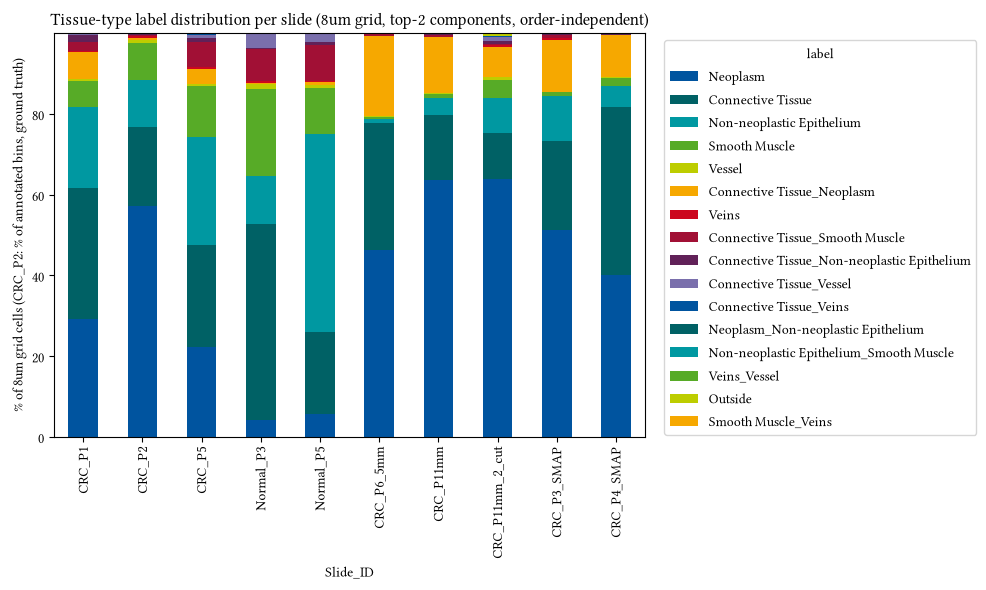

In [4]:
# Bin-level (8um grid) label distribution, all 10 available slides -- CRC_P3_SMAP/
# CRC_P4_SMAP's grid label transfer has already been run (lt.main_grid(), see
# new_single_omics.ipynb), so no recomputation needed here, just reading its output.
ALL_SAMPLES = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5",
               "CRC_P6_5mm", "CRC_P11mm", "CRC_P11mm_2_cut", "CRC_P3_SMAP", "CRC_P4_SMAP"]

def canonical_top2(labels):
    # collapse to top 2 labels (e.g. veins_muscle_vessel and veins_muscle_neoplasm is veins_muscle)
    top2 = labels.astype(str).str.split("_").str[:2]
    return top2.apply(lambda parts: "_".join(sorted(parts)))

grid_gt_008um = lt.aggregate_bin_annotation_to_grid(reference_sample="CRC_P2", group_size=4)  # 4 x 2um = 8um
crc_p2_grid_dist = canonical_top2(grid_gt_008um["annotation"]).value_counts(normalize=True) * 100
crc_p2_grid_dist.name = "CRC_P2"

grid_dist_rows = [crc_p2_grid_dist]
for sample_id in ALL_SAMPLES:
    if sample_id == "CRC_P2":
        continue
    pred_path = label_transfer_dir(sample_id) / f"{sample_id}_grid_predictions.parquet"
    if not pred_path.exists():
        print(f"{sample_id}: no _grid_predictions.parquet yet -- skipping")
        continue
    grid_pred = pd.read_parquet(pred_path, columns=["predicted_tissuetype_grid_image"])
    dist = canonical_top2(grid_pred["predicted_tissuetype_grid_image"]).value_counts(normalize=True) * 100
    dist.name = sample_id
    grid_dist_rows.append(dist)

label_dist_grid = pd.concat(grid_dist_rows, axis=1).T.reindex(ALL_SAMPLES).fillna(0)

from matplotlib.colors import ListedColormap
n_labels = label_dist_grid.shape[1]
palette = ListedColormap([pl.RWTH_CATEGORICAL[i % len(pl.RWTH_CATEGORICAL)] for i in range(n_labels)])

ax = label_dist_grid.plot(kind="bar", stacked=True, figsize=(10, 6), colormap=palette)
ax.set_ylabel("% of 8um grid cells (CRC_P2: % of annotated bins, ground truth)")
ax.set_xlabel("Slide_ID")
ax.set_title("Tissue-type label distribution per slide (8um grid, top-2 components, order-independent)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="label")
plt.tight_layout()
plt.show()

## Transcriptomics

In this first part of the evaluation, we check the preprocessing of the transcriptomics. 
As a first step, we 

/tmp/ipykernel_47298/1057695709.py:16: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
/tmp/ipykernel_47298/1057695709.py:16: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
/tmp/ipykernel_47298/1057695709.py:16: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
/tmp/ipykernel_47298/1057695709.py:16: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
/tmp/ipykernel_47298/1057695709.py:16: UserWarning: Variable nam

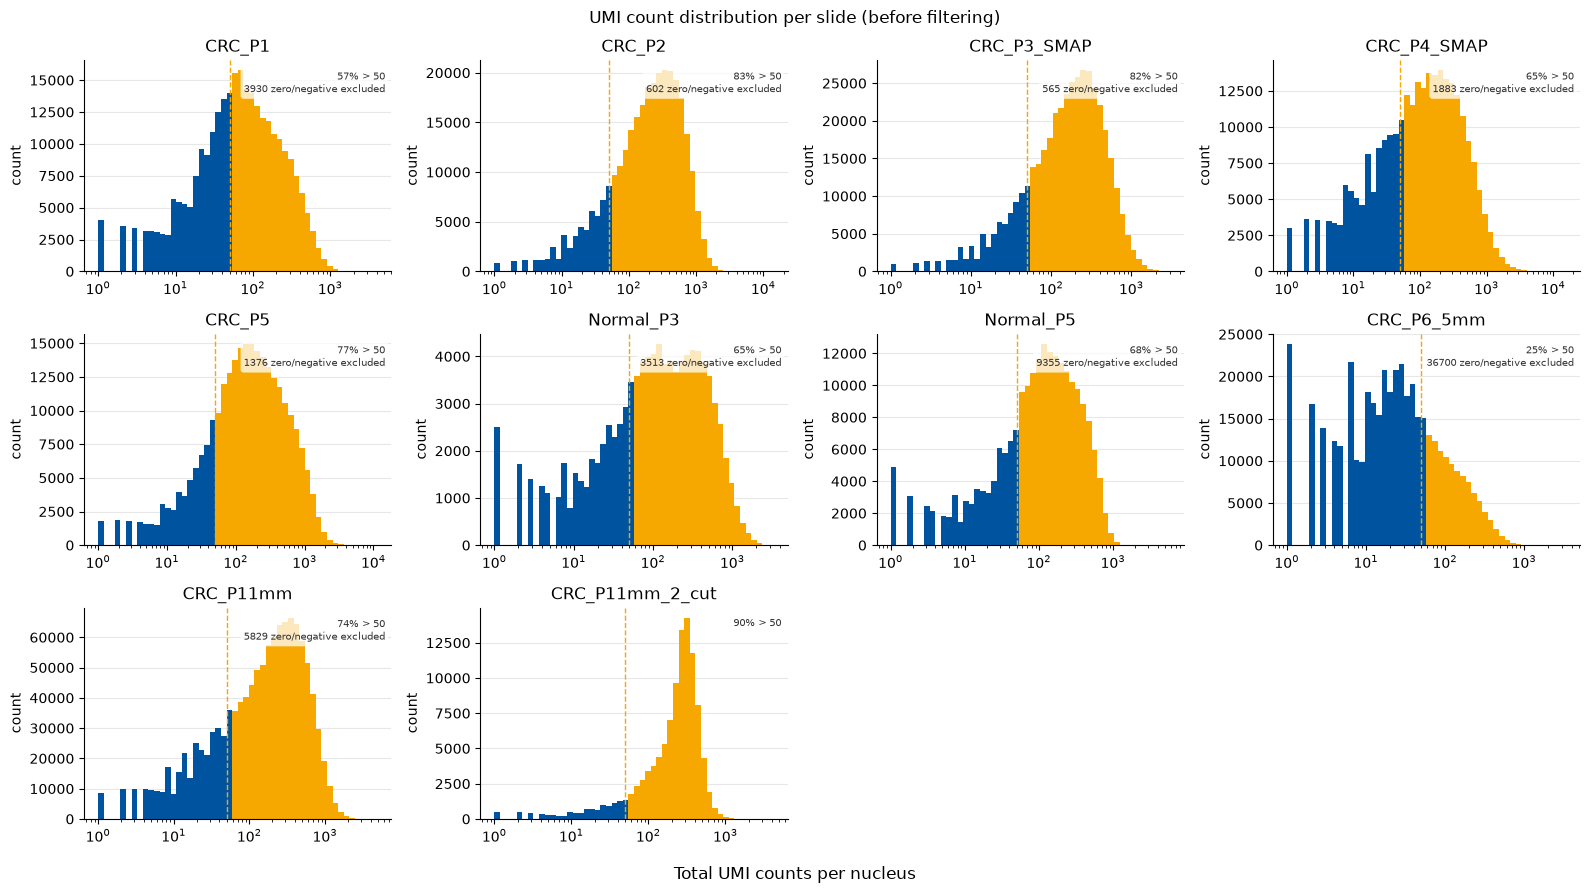

In [5]:
# Plot UMI count distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
import pickle
import geopandas as gpd
from shapely.geometry import Polygon

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
dir_cellseg = "01_preprocessing/cell_seg_stardist/002um"
UMI_CUTOFF = 50   # matches the actual filter applied in CustomBinning.ipynb (total_counts > 50)
AREA_CUTOFF = 500  # matches the actual filter applied in CustomBinning.ipynb (area < 500 px^2)

# nuclei_grouped_UMI_count.h5ad has no total_counts/area saved -- both need to be
# computed here, same as CustomBinning.ipynb does. Area only exists via the raw
# StarDist polygons (polys_FullSection.pckl), joined onto the UMI-count population by id.
qc_by_slide = {}
for sample_id in samples:
    adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
    sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

    with open(basedir / sample_id / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
        polys = pickle.load(f)
    geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
    gdf = gpd.GeoDataFrame({"id": [f"ID_{i+1}" for i in range(len(geometries))], "area": gpd.GeoSeries(geometries).area})

    qc_by_slide[sample_id] = adata.obs[["id", "total_counts", "n_genes_by_counts"]].merge(gdf, on="id", how="left")
    del adata, polys, geometries, gdf
    gc.collect()

pl.plot_distribution_grid(
    {s: df["total_counts"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Total UMI counts per nucleus",
    title="UMI count distribution per slide (before filtering)",
    cutoff=UMI_CUTOFF,
    log_x=True,
)
plt.show()


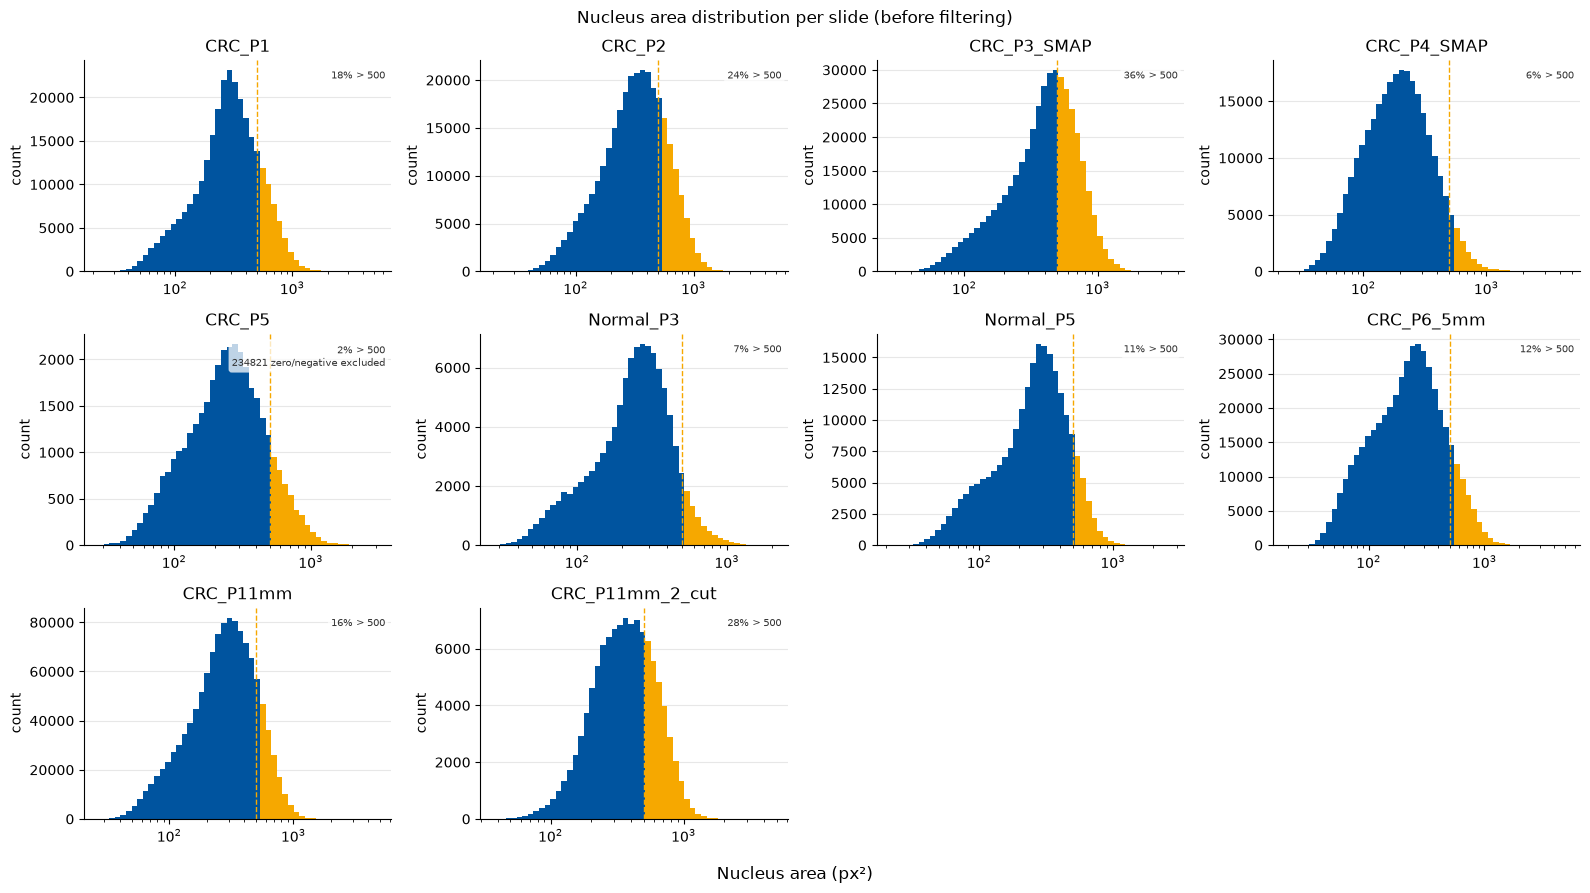

In [6]:
# Plot cell size distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
pl.plot_distribution_grid(
    {s: df["area"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Nucleus area (px²)",
    title="Nucleus area distribution per slide (before filtering)",
    cutoff=AREA_CUTOFF,
    log_x=True,
)
plt.show()


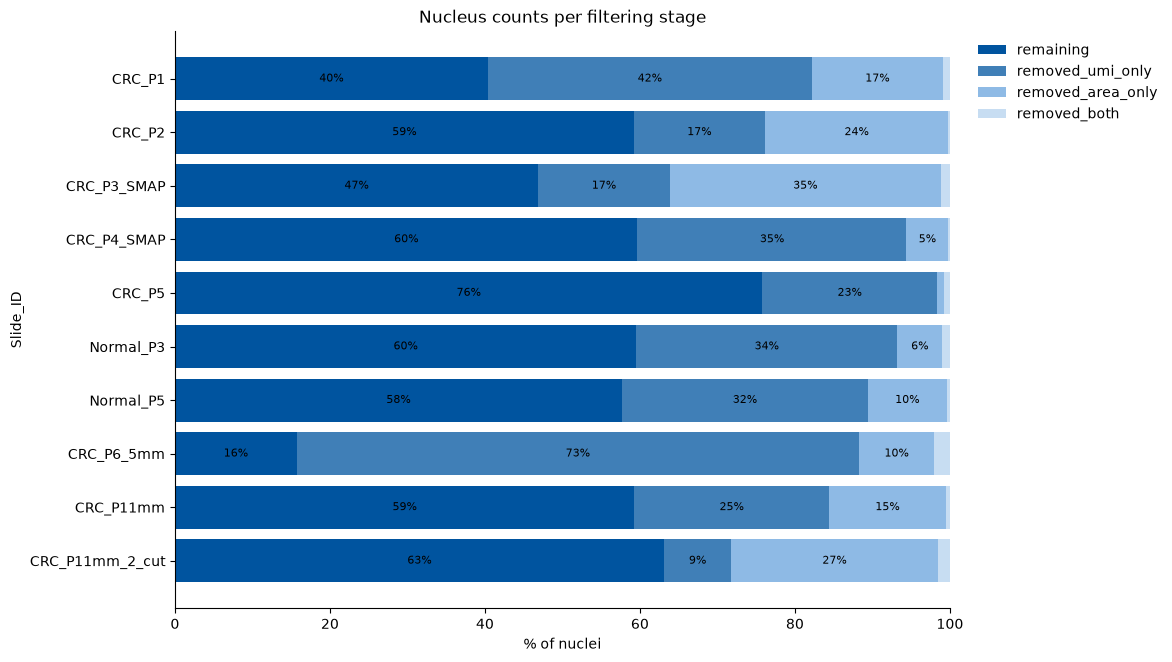

,remaining,removed_umi_only,removed_area_only,removed_both
Slide_ID,,,,
CRC_P1,116789,121002,48979,2635
CRC_P2,180892,51732,72318,678
CRC_P3_SMAP,199041,72182,148598,5049
CRC_P4_SMAP,165241,96128,14858,676
CRC_P5,205359,61044,2424,2151
Normal_P3,61849,35006,6049,1034
Normal_P5,130106,71600,22972,951
CRC_P6_5mm,72099,333156,44661,9341
CRC_P11mm,708257,300380,180227,6344


In [8]:
# plot cell count per slide:
# 1. total before filtering
# 2. removed through UMI filter
# 3. removed through size filter
# 4. total left
funnel_rows = []
for sample_id, df in qc_by_slide.items():
    fail_umi = df["total_counts"] <= UMI_CUTOFF
    fail_area = df["area"] >= AREA_CUTOFF
    funnel_rows.append({
        "Slide_ID": sample_id,
        "remaining": (~fail_umi & ~fail_area).sum(),
        "removed_umi_only": (fail_umi & ~fail_area).sum(),
        "removed_area_only": (~fail_umi & fail_area).sum(),
        "removed_both": (fail_umi & fail_area).sum(),
    })

funnel_df = pd.DataFrame(funnel_rows).set_index("Slide_ID")
pl.plot_filter_funnel(funnel_df, title="Nucleus counts per filtering stage")
plt.show()
funnel_df


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


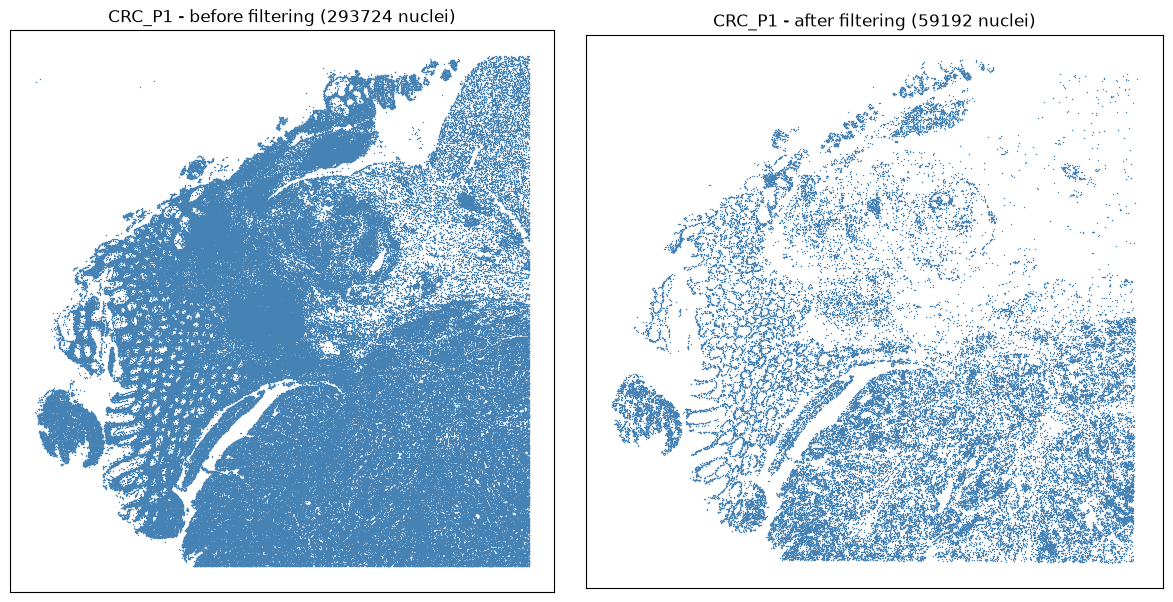

6

In [9]:
# for a chosen cell: plot all cells (dots can all have the same color) based on their spatial coordinates
# - befire filtering
# - after filtering
sample_trans = samples[0]  # change to inspect a different slide

with open(basedir / sample_trans / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)
geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
before_centroids = gpd.GeoSeries(geometries).centroid
before_coords = np.stack([before_centroids.x.to_numpy(), before_centroids.y.to_numpy()], axis=1)

# Restrict "before filtering" to nuclei within the valid barcoding range (tissue_positions.parquet),
# same bounding box CustomBinning.ipynb uses for its own ROI plots -- excludes nuclei that fall
# outside where the Visium HD barcode grid actually has valid (mapped) positions.
tissue_positions = pd.read_parquet(basedir / sample_trans / "output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
valid = tissue_positions.loc[tissue_positions["pxl_col_in_fullres"] > 0, ["pxl_col_in_fullres", "pxl_row_in_fullres"]]
x_min, x_max = valid["pxl_col_in_fullres"].min(), valid["pxl_col_in_fullres"].max()
y_min, y_max = valid["pxl_row_in_fullres"].min(), valid["pxl_row_in_fullres"].max()
in_range = (
    (before_coords[:, 0] >= x_min) & (before_coords[:, 0] <= x_max) &
    (before_coords[:, 1] >= y_min) & (before_coords[:, 1] <= y_max)
)
before_coords = before_coords[in_range]

after_adata = sc.read_h5ad(basedir / sample_trans / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")
after_coords = np.asarray(after_adata.obsm["spatial"])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pl.plot_spatial_points(before_coords, ax=axes[0], title=f"{sample_trans} - before filtering ({len(before_coords)} nuclei)")
pl.plot_spatial_points(after_coords, ax=axes[1], title=f"{sample_trans} - after filtering ({len(after_coords)} nuclei)")
plt.tight_layout()
plt.show()

del polys, geometries, before_centroids, tissue_positions
gc.collect()


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/fu

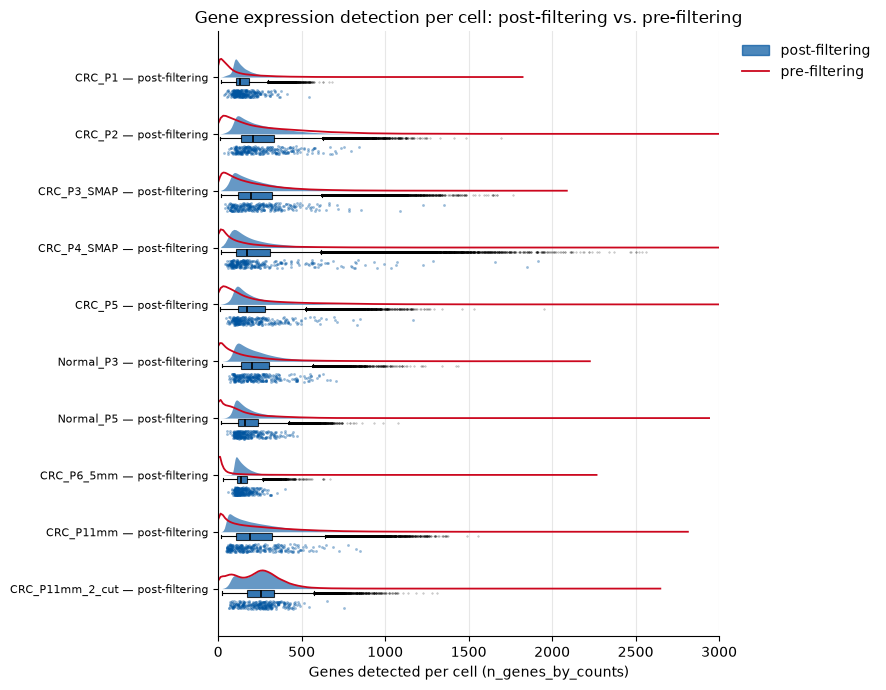

In [11]:
# Gene expression distribution per cell: how many genes are detected (nonzero) per cell,
# pre- vs. post-filtering, per slide. Pre-filtering reuses n_genes_by_counts already
# computed in qc_by_slide (cell above); post-filtering comes straight from
# count_area_filtered_adata.h5ad, which already has it saved.
genes_by_slide = {}
for sample_id in samples:
    post = sc.read_h5ad(
        basedir / sample_id / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r"
    ).obs["n_genes_by_counts"]
    genes_by_slide[sample_id] = {
        "pre-filtering": qc_by_slide[sample_id]["n_genes_by_counts"].to_numpy(),
        "post-filtering": post.to_numpy(),
    }

# One row per slide (post-filtering's full cloud+box+rain, in blue), with
# pre-filtering overlaid as a red density line on the same row instead of its
# own separate cloud+box+rain -- shows the filtering shift directly, in one plot.
XLIM = (0, 3000)
ax = pl.plot_raincloud_grid(
    {sample_id: {"post-filtering": stages["post-filtering"]} for sample_id, stages in genes_by_slide.items()},
    xlabel="Genes detected per cell (n_genes_by_counts)",
    title="Gene expression detection per cell: post-filtering vs. pre-filtering",
    xlim=XLIM,
)

from scipy.stats import gaussian_kde
PRE_FILTER_COLOR = pl.RWTH_ACCENT_COLORS[5]  # red
n_rows = len(genes_by_slide)
for i, (sample_id, stages) in enumerate(genes_by_slide.items()):
    y0 = n_rows - i  # matches plot_raincloud_grid's own top-to-bottom row placement
    pre_values = stages["pre-filtering"]
    pre_values = pre_values[np.isfinite(pre_values)]
    if len(pre_values) < 2 or np.ptp(pre_values) == 0:
        continue
    kde = gaussian_kde(pre_values)
    grid_max = min(pre_values.max(), XLIM[1])
    x_grid = np.linspace(pre_values.min(), grid_max, 200)
    density = kde(x_grid)
    density = density / density.max() * 0.32  # same scaling plot_raincloud_grid uses for its cloud
    ax.plot(x_grid, y0 + density, color=PRE_FILTER_COLOR, linewidth=1.3)

# plot_raincloud_grid already drew its own single-stage legend (post-filtering only) --
# replace it with one covering both, rather than layering a second legend on top.
post_color = pl.RWTH_CATEGORICAL[0]
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=post_color, alpha=0.7),
                  plt.Line2D([0], [0], color=PRE_FILTER_COLOR, linewidth=1.3)]
ax.legend(legend_handles, ["post-filtering", "pre-filtering"],
          bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

### SVG distribution & cross-slide comparison
Addresses the two remaining TODO items above. Follows a 3-level breakdown (per-slide burden -> cross-slide reproducibility -> healthy-vs-diseased repertoire), reusing the SVG union already computed by the autoencoder pipeline (`functions.dual_autoencoder.get_svg_union_mask`, ~539 genes -- flagged as spatially variable, Moran's I FDR-corrected p < 0.05 and I > 0.1, in at least one of the 10 slides) rather than recomputing SVG calling here. All numbers below come from `data/combined/.../count_area_filtered_adata.h5ad`'s `varm['moranI_per_sample']` / `varm['moranI_pval_fdr_per_sample']` / `varm['spatially_variable_per_sample']` (column order given by `uns['sample_order']`) -- the same per-slide Moran's I matrices `get_svg.py` / `CustomBinning.ipynb`'s merge step already produced, so SVG-calling parameters (bin size, QC filtering, neighbor graph, FDR threshold) are guaranteed consistent across slides by construction.

**`svg_long` columns**: `gene` -- the gene symbol (one of the 539 union genes). `Slide_ID` / `condition` -- which slide/CRC-or-Normal this row's Moran's I was computed on (one row per gene-slide *pair*, so each gene has 10 rows -- `svg_long.head()` only shows the first gene's first 5 rows, i.e. its first 5 slides in `sample_order`; that's a display truncation, not a real restriction to those slides -- all 10 are in there and used throughout). `moranI` / `moranI_pval_fdr` -- that gene-slide's Moran's I statistic and FDR-corrected p-value. `is_svg` -- whether *this slide* individually called the gene spatially variable (I > 0.1 and FDR p < 0.05); a gene is in the 539-gene union if `is_svg` is True for at least one slide, which is what the prevalence/reproducibility analysis below is built on.

**Moran's I** measures spatial autocorrelation: whether nearby bins/cells have similar expression (near 0 = spatially random, near 1 = strongly clustered/patterned, negative = checkerboard-like). It's the actual statistic SVG calling thresholds on. Plotting its full per-slide *distribution* (section A, over all 18085 tested genes, not just the 539-gene union) is a QC check independent of the fixed 0.1/FDR<0.05 cutoff: it shows whether a slide's overall spatial-structure profile looks like the others, e.g. a slide with a systematically shifted distribution could be flagged even before individual SVG counts diverge.

In [12]:
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import pdist, squareform

from functions.dual_autoencoder import get_svg_union_mask

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
trans_combined = sc.read_h5ad(
    basedir / "combined" / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r"
)

sample_order = list(trans_combined.uns["sample_order"])
conditions = {s: lt.get_disease_status(s) for s in sample_order}  # "CRC" or "Normal"

svg_union_mask = get_svg_union_mask(trans_combined)
svg_genes = trans_combined.var_names[svg_union_mask].to_numpy()

moranI = np.asarray(trans_combined.varm["moranI_per_sample"])[svg_union_mask]
moranI_fdr = np.asarray(trans_combined.varm["moranI_pval_fdr_per_sample"])[svg_union_mask]
is_svg = np.asarray(trans_combined.varm["spatially_variable_per_sample"])[svg_union_mask].astype(bool)

# long-form table: one row per (gene, slide), restricted to the union -- the
# "feature universe" for everything below, avoids ever plotting all 18k tested genes
svg_long = pd.DataFrame({
    "gene": np.repeat(svg_genes, len(sample_order)),
    "Slide_ID": np.tile(sample_order, len(svg_genes)),
})
svg_long["condition"] = svg_long["Slide_ID"].map(conditions)
svg_long["moranI"] = moranI.ravel()
svg_long["moranI_pval_fdr"] = moranI_fdr.ravel()
svg_long["is_svg"] = is_svg.ravel()

print(f"SVG union: {len(svg_genes)} genes across {len(sample_order)} slides "
      f"({sum(c == 'CRC' for c in conditions.values())} CRC / "
      f"{sum(c == 'Normal' for c in conditions.values())} Normal)")
svg_long.head()

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SVG union: 539 genes across 10 slides (8 CRC / 2 Normal)


,gene,Slide_ID,condition,moranI,moranI_pval_fdr,is_svg
0,ISG15,CRC_P1,CRC,0.013569,0.005016,False
1,ISG15,CRC_P2,CRC,0.085534,0.002876,False
2,ISG15,CRC_P5,CRC,0.015122,0.003305,False
3,ISG15,Normal_P3,Normal,0.145232,0.003901,True
4,ISG15,Normal_P5,Normal,-0.000636,0.393176,False


#### A. SVG burden per slide
Before comparing slide-to-slide, check whether SVG counts track QC/coverage rather than biology -- a slide with more cells or higher sequencing depth can produce more significant genes independent of tissue.

In [13]:
# per-slide burden table: tested genes, SVG count/fraction, effect-size and
# significance summaries (over ALL 18085 tested genes, not just the union --
# the union would bias median/max upward by construction), plus QC covariates
# so a high/low SVG count can be sanity-checked against coverage
all_moranI = np.asarray(trans_combined.varm["moranI_per_sample"])
all_moranI_fdr = np.asarray(trans_combined.varm["moranI_pval_fdr_per_sample"])
all_is_svg = np.asarray(trans_combined.varm["spatially_variable_per_sample"]).astype(bool)

n_tested = (~np.isnan(all_moranI)).sum(axis=0)
n_svg = all_is_svg.sum(axis=0)
median_I = np.nanmedian(all_moranI, axis=0)
max_I = np.nanmax(all_moranI, axis=0)
median_neg_log10_q = np.nanmedian(-np.log10(np.clip(all_moranI_fdr, 1e-300, None)), axis=0)

qc_per_slide = trans_combined.obs[["Slide_ID", "total_counts", "n_genes_by_counts"]].groupby(
    "Slide_ID", observed=True
).agg(
    n_cells=("total_counts", "size"),
    median_total_counts=("total_counts", "median"),
    median_n_genes=("n_genes_by_counts", "median"),
).reindex(sample_order)

svg_summary = pd.DataFrame({
    "Slide_ID": sample_order,
    "condition": [conditions[s] for s in sample_order],
    "n_tested_genes": n_tested,
    "n_svg": n_svg,
    "frac_svg": n_svg / n_tested,
    "median_moranI": median_I,
    "max_moranI": max_I,
    "median_neg_log10_q": median_neg_log10_q,
}).set_index("Slide_ID").join(qc_per_slide).sort_values("n_svg", ascending=False)

svg_summary

,condition,n_tested_genes,n_svg,frac_svg,median_moranI,max_moranI,median_neg_log10_q,n_cells,median_total_counts,median_n_genes
Slide_ID,,,,,,,,,,
Normal_P3,Normal,17819,232,0.013020,0.001982,0.774824,0.848427,46535,276.0,201.0
CRC_P4_SMAP,CRC,16568,222,0.013399,0.002689,0.886930,2.001226,151436,242.0,172.0
CRC_P3_SMAP,CRC,18008,214,0.011884,0.002250,0.900450,1.925958,295975,237.0,197.0
CRC_P2,CRC,18022,183,0.010154,0.001939,0.780421,1.705674,144296,249.0,211.0
CRC_P5,CRC,18033,166,0.009205,0.001792,0.648628,1.182353,115498,225.0,174.0
CRC_P1,CRC,17743,143,0.008060,0.000407,0.805817,1.659952,59192,162.0,133.0
Normal_P5,Normal,18041,141,0.007816,0.001423,0.648397,1.196256,91360,204.0,161.0
CRC_P11mm_2_cut,CRC,17903,115,0.006424,0.001456,0.784498,0.861395,89106,279.0,258.0
CRC_P11mm,CRC,17419,88,0.005052,0.001127,0.755421,1.658899,708257,210.0,191.0


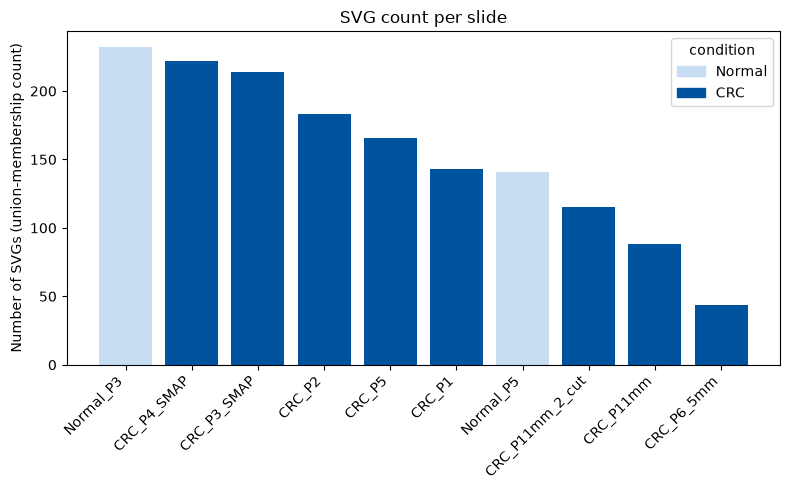

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Normal": pl.RWTH_BLUE_RAMP[3], "CRC": pl.RWTH_BLUE_RAMP[0]}  # blue first, then red
bars = svg_summary["n_svg"]
ax.bar(bars.index, bars.values, color=[colors[c] for c in svg_summary["condition"]])
ax.set_ylabel("Number of SVGs (union-membership count)")
ax.set_title("SVG count per slide")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], title="condition")
plt.tight_layout()
plt.show()

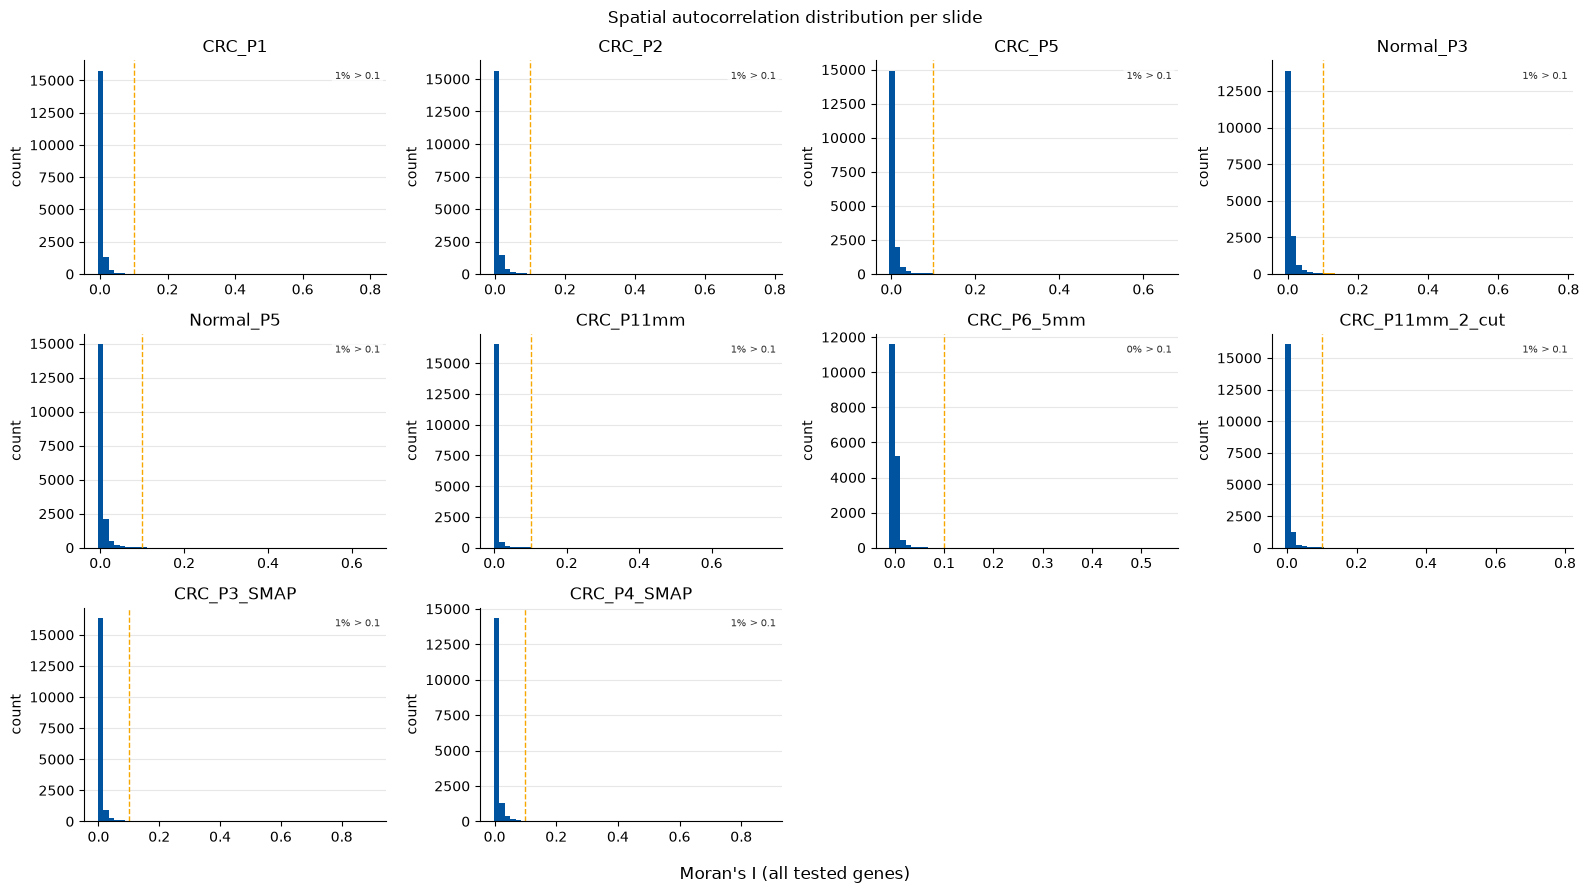

In [30]:
# Moran's I distribution per slide, over ALL tested genes (not just the SVG union) --
# shows whether a slide's overall spatial-autocorrelation profile looks like the others,
# independent of the fixed 0.1/FDR<0.05 cutoff used to call individual genes SVGs.
pl.plot_distribution_grid(
    {s: all_moranI[:, i][~np.isnan(all_moranI[:, i])] for i, s in enumerate(sample_order)},
    xlabel="Moran's I (all tested genes)",
    title="Spatial autocorrelation distribution per slide",
    cutoff=0.1,
    log_x=False,
)
plt.show()

#### B. SVG reproducibility across slides
Which SVGs are shared, and which are slide-specific? `upsetplot` isn't in this environment, so set membership is summarized with prevalence-threshold categories instead of a true UpSet plot (`pip install upsetplot` would enable one if useful later -- the categories below answer the same question).

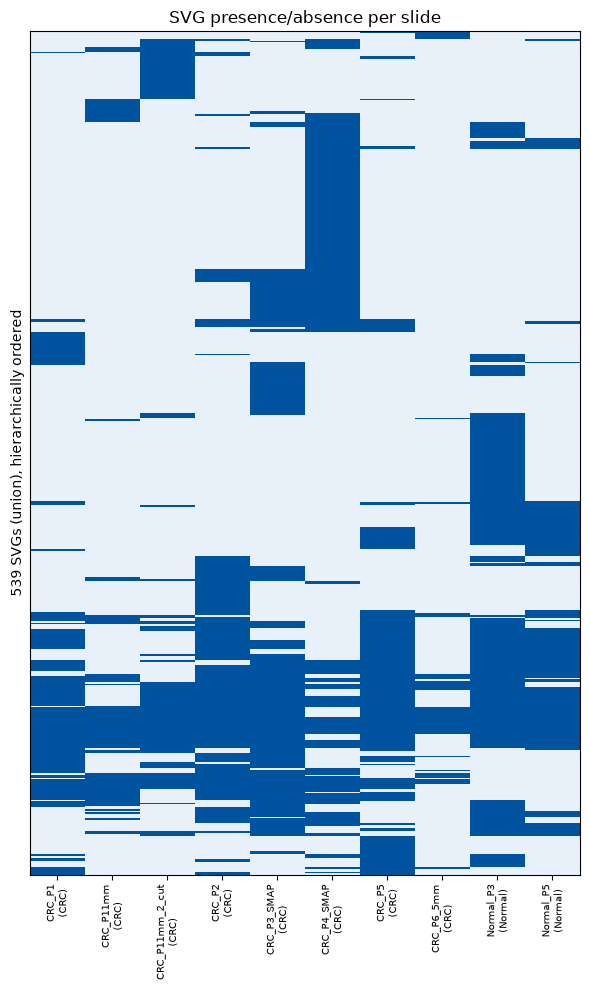

In [31]:
# binary presence heatmap: genes (rows) x slides (columns), rows ordered by
# hierarchical clustering on co-occurrence so reproducible blocks are visible;
# columns grouped by condition rather than interleaved
presence = is_svg.astype(float)  # (n_genes, n_samples), same row order as svg_genes
order = sorted(range(len(sample_order)), key=lambda i: (conditions[sample_order[i]], sample_order[i]))
presence_ordered = presence[:, order]
cols_ordered = [sample_order[i] for i in order]

row_linkage = linkage(presence_ordered, method="average", metric="jaccard")
row_order = leaves_list(row_linkage)

fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(presence_ordered[row_order], aspect="auto", cmap=pl.rwth_blue_cmap(), interpolation="none")
ax.set_xticks(range(len(cols_ordered)))
ax.set_xticklabels(
    [f"{s}\n({conditions[s]})" for s in cols_ordered], rotation=90, fontsize=7
)
ax.set_yticks([])
ax.set_ylabel(f"{len(svg_genes)} SVGs (union), hierarchically ordered")
ax.set_title("SVG presence/absence per slide")
plt.tight_layout()
plt.show()

shared-core (>=80% of all slides)              44
disease-core (>=80% of CRC slides)             34
healthy-core (>=80% of Normal slides)         122
disease-enriched (>=80% CRC, <=20% Normal)      7
healthy-enriched (>=80% Normal, <=20% CRC)     32
slide-specific (exactly 1 slide)              232
dtype: int64


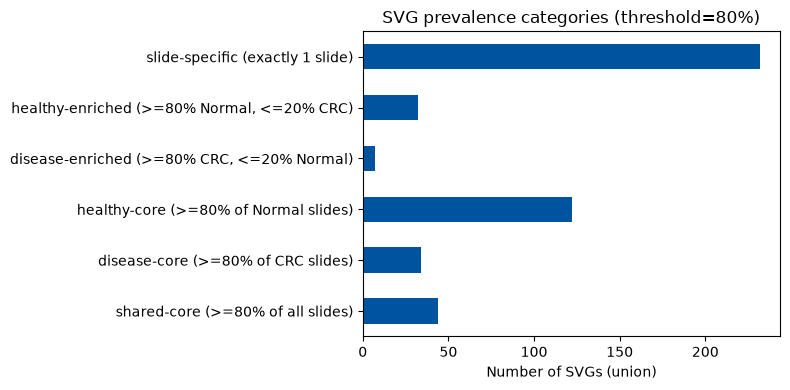

In [32]:
# Prevalence-threshold categories (condition-aware "UpSet" summary): a gene
# counts as belonging to a category if it's an SVG in >=80% of the relevant
# slide group. With only 2 Normal slides, ">=80% of healthy" means both.
PREVALENCE_THRESH = 0.8
n_crc = sum(c == "CRC" for c in conditions.values())
n_normal = sum(c == "Normal" for c in conditions.values())
crc_cols = [i for i, s in enumerate(sample_order) if conditions[s] == "CRC"]
normal_cols = [i for i, s in enumerate(sample_order) if conditions[s] == "Normal"]

frac_all = is_svg.mean(axis=1)
frac_crc = is_svg[:, crc_cols].mean(axis=1)
frac_normal = is_svg[:, normal_cols].mean(axis=1)
n_slides_hit = is_svg.sum(axis=1)

categories = {
    "shared-core (>=80% of all slides)": frac_all >= PREVALENCE_THRESH,
    "disease-core (>=80% of CRC slides)": frac_crc >= PREVALENCE_THRESH,
    "healthy-core (>=80% of Normal slides)": frac_normal >= PREVALENCE_THRESH,
    "disease-enriched (>=80% CRC, <=20% Normal)": (frac_crc >= PREVALENCE_THRESH) & (frac_normal <= 0.2),
    "healthy-enriched (>=80% Normal, <=20% CRC)": (frac_normal >= PREVALENCE_THRESH) & (frac_crc <= 0.2),
    "slide-specific (exactly 1 slide)": n_slides_hit == 1,
}
cat_counts = pd.Series({k: v.sum() for k, v in categories.items()})
print(cat_counts)

fig, ax = plt.subplots(figsize=(8, 4))
cat_counts.plot(kind="barh", ax=ax, color=pl.RWTH_CATEGORICAL[0])
ax.set_xlabel("Number of SVGs (union)")
ax.set_title(f"SVG prevalence categories (threshold={PREVALENCE_THRESH:.0%})")
plt.tight_layout()
plt.show()

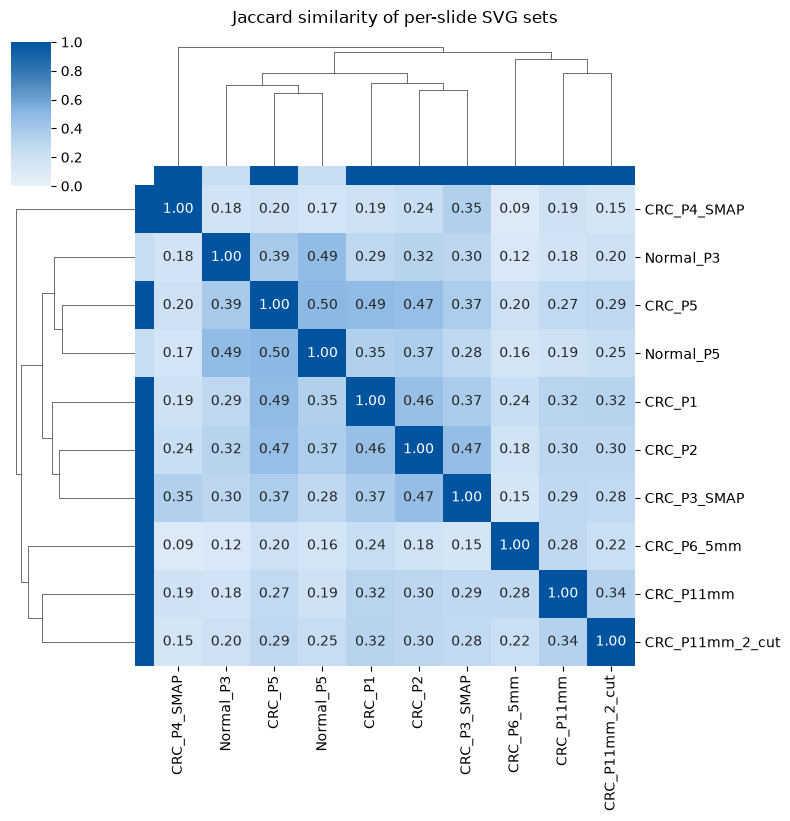

In [33]:
# Jaccard similarity between slides' SVG sets, with hierarchical clustering --
# slides clustering by condition (rather than by patient/batch/depth) supports a
# condition-associated SVG repertoire; a slide dissimilar to everyone else is
# worth investigating individually (c.f. CRC_P6_5mm's QC-driven low SVG count above)
jaccard_dist = pdist(is_svg.T, metric="jaccard")  # slides x slides, over the SVG union
jaccard_sim = 1 - squareform(jaccard_dist)
jaccard_df = pd.DataFrame(jaccard_sim, index=sample_order, columns=sample_order)

g = sns.clustermap(
    jaccard_df, cmap=pl.rwth_blue_cmap(), vmin=0, vmax=1,
    row_colors=[colors[conditions[s]] for s in sample_order],
    col_colors=[colors[conditions[s]] for s in sample_order],
    figsize=(8, 8), annot=True, fmt=".2f",
)
g.fig.suptitle("Jaccard similarity of per-slide SVG sets", y=1.02)
plt.show()

#### C. Healthy vs. diseased SVG repertoire
Distinguishes genes by *membership* (SVG in one condition but not the other) rather than raw counts.

In [ ]:
# prevalence scatter: p_H(g) vs p_D(g), one point per SVG in the union
prevalence_df = pd.DataFrame({
    "gene": svg_genes,
    "p_normal": frac_normal,
    "p_crc": frac_crc,
}).set_index("gene")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(prevalence_df["p_normal"], prevalence_df["p_crc"], s=15, alpha=0.5, color="#444444")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
ax.set_xlabel("fraction of Normal slides calling gene SVG")
ax.set_ylabel("fraction of CRC slides calling gene SVG")
ax.set_title("SVG prevalence: healthy vs. diseased")

# label the most prevalence-divergent genes on each side of the diagonal
prevalence_df["diff"] = prevalence_df["p_crc"] - prevalence_df["p_normal"]
for _, row in prevalence_df.reindex(prevalence_df["diff"].abs().sort_values(ascending=False).index[:12]).iterrows():
    ax.annotate(row.name, (row["p_normal"], row["p_crc"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

In [ ]:
# dot plot of representative genes from each repertoire category -- top N by
# prevalence-difference (or overall prevalence for the shared set), avoids
# plotting all 539 genes at once
TOP_N = 15
disease_enriched_genes = prevalence_df.sort_values("diff", ascending=False).index[:TOP_N]
healthy_enriched_genes = prevalence_df.sort_values("diff", ascending=True).index[:TOP_N]
shared_genes = prevalence_df.loc[(prevalence_df["p_crc"] >= 0.8) & (prevalence_df["p_normal"] >= 0.8)] \
    .assign(mean_p=lambda d: (d["p_crc"] + d["p_normal"]) / 2) \
    .sort_values("mean_p", ascending=False).index[:TOP_N]

dot_genes = pd.Index(list(shared_genes) + list(healthy_enriched_genes) + list(disease_enriched_genes)).unique()
dot_rows = []
for gene in dot_genes:
    for cond, cols in [("Normal", normal_cols), ("CRC", crc_cols)]:
        gi = np.where(svg_genes == gene)[0][0]
        dot_rows.append({
            "gene": gene,
            "condition": cond,
            "prevalence": is_svg[gi, cols].mean(),
            "median_moranI": np.nanmedian(moranI[gi, cols]),
        })
dot_df = pd.DataFrame(dot_rows)

fig, ax = plt.subplots(figsize=(max(6, len(dot_genes) * 0.3), 4))
y_pos = {"Normal": 0, "CRC": 1}
sizes = 20 + dot_df["prevalence"] * 200
sc_plot = ax.scatter(
    [list(dot_genes).index(g) for g in dot_df["gene"]],
    [y_pos[c] for c in dot_df["condition"]],
    s=sizes, c=dot_df["median_moranI"], cmap=pl.rwth_blue_yellow_cmap(), edgecolors="black", linewidths=0.3,
)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Normal", "CRC"])
ax.set_xticks(range(len(dot_genes)))
ax.set_xticklabels(dot_genes, fontsize=7, rotation=90)
ax.set_ylim(-0.5, 1.5)
ax.set_title(f"top {TOP_N} shared / healthy-enriched / disease-enriched SVGs")
plt.colorbar(sc_plot, ax=ax, label="median Moran's I")
plt.tight_layout()
plt.show()

#### D. Spatial expression panels for representative genes
A gene being an SVG doesn't say *where* its spatial pattern sits -- spot-check one gene per repertoire category on real tissue. Picks the top gene from each category found above; edit `GENES_TO_PLOT` to inspect others. Uses each slide's own `count_area_filtered_adata.h5ad` (not the backed combined file) since this needs actual expression values, not just the precomputed Moran's I summaries.

In [ ]:
GENES_TO_PLOT = {
    "shared-core": shared_genes[0],
    "healthy-enriched": healthy_enriched_genes[0],
    "disease-enriched": disease_enriched_genes[0],
}
PANEL_SLIDES = ["Normal_P3", "Normal_P5", "CRC_P1", "CRC_P2"]  # 2 healthy, 2 diseased

fig, axes = plt.subplots(len(GENES_TO_PLOT), len(PANEL_SLIDES), figsize=(4 * len(PANEL_SLIDES), 4 * len(GENES_TO_PLOT)))
for row, (label, gene) in enumerate(GENES_TO_PLOT.items()):
    # shared color scale across all 4 slides for this gene, not per-panel
    vals_per_slide = {}
    for sample_id in PANEL_SLIDES:
        a = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")
        gi = a.var_names.get_loc(gene)
        col = a[:, gi].X  # sliced column is a small sparse matrix even though a.X (whole panel) is backed
        expr = np.asarray(col.toarray() if hasattr(col, "toarray") else col).ravel()
        vals_per_slide[sample_id] = (np.asarray(a.obsm["spatial"]), expr)
    vmax = max(expr.max() for _, expr in vals_per_slide.values())

    for col, sample_id in enumerate(PANEL_SLIDES):
        spatial, expr = vals_per_slide[sample_id]
        ax = axes[row, col]
        sc_plot = ax.scatter(spatial[:, 0], spatial[:, 1], c=expr, cmap=pl.rwth_blue_yellow_cmap(), s=1, vmin=0, vmax=vmax)
        ax.set_title(f"{sample_id}\n{gene} ({label})", fontsize=9)
        ax.invert_yaxis()
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc_plot, ax=axes[row, :].tolist(), shrink=0.6, label="expression")

plt.show()